# Notebook 08 — Existing Models

**Purpose:** Train and evaluate seven diverse ML models with default/reasonable hyperparameters. Generate OOF predictions for hybrid model training.

**Inputs:** Engineered dataset, train/test indices, selected features

**Outputs:**
- Trained model artifacts (`models/base_models/`)
- OOF predictions for all models (`results/metrics/08_oof_predictions.csv`)
- Model comparison table (`results/metrics/08_model_comparison.csv`)


In [1]:
import sys, os, time
sys.path.insert(0, os.path.abspath(".."))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.model_selection import cross_val_predict
import xgboost as xgb
import lightgbm as lgbm
from catboost import CatBoostClassifier

from src.config import *
from src.data_utils import (
    ALL_ORIGINAL_FEATURES, ENGINEERED_FEATURES,
    build_preprocessing_pipeline, get_cv_splitter,
    save_artifact, load_artifact, CONTINUOUS_FEATURES,
)
from src.evaluation import compute_all_metrics, metrics_to_dataframe, print_confusion_matrix
from src.plotting import (
    plot_confusion_matrix, plot_roc_curves, plot_pr_curves,
    plot_metric_comparison, save_figure,
)

seed_everything()

# Load data
df = pd.read_csv(os.path.join(DATA_PROCESSED, "df1_engineered.csv"))
train_idx = np.load(os.path.join(DATA_PROCESSED, "train_indices.npy"))
test_idx = np.load(os.path.join(DATA_PROCESSED, "test_indices.npy"))
FEATURES = load_artifact(os.path.join(MODELS_PREPROC, "selected_features.joblib"))

X_train = df.loc[train_idx, FEATURES].copy()
y_train = df.loc[train_idx, TARGET_COL].copy()
X_test = df.loc[test_idx, FEATURES].copy()
y_test = df.loc[test_idx, TARGET_COL].copy()

# Preprocess for models that need scaling (LR, SVM)
preprocessor = build_preprocessing_pipeline(FEATURES)
preprocessor.fit(X_train)
X_train_pp = preprocessor.transform(X_train)
X_test_pp = preprocessor.transform(X_test)

cv = get_cv_splitter()
print(f"Features: {len(FEATURES)}")
print(f"Training: {X_train.shape[0]:,}  |  Test: {X_test.shape[0]:,}")


Features: 29
Training: 202,944  |  Test: 50,736


## 8.1 Model Definitions

We train 7 diverse classifiers:
1. **Logistic Regression** — linear baseline
2. **Decision Tree** — simple non-linear baseline
3. **Random Forest** — bagging ensemble
4. **SVM** — margin-based classifier (important for research hypothesis)
5. **XGBoost** — gradient boosting
6. **LightGBM** — gradient boosting (leaf-wise)
7. **CatBoost** — gradient boosting (ordered boosting)


In [2]:
# Compute class weights for models that support sample_weight
from sklearn.utils.class_weight import compute_sample_weight

sample_weights_train = compute_sample_weight("balanced", y_train)

# Class weight dict for CatBoost
class_counts = y_train.value_counts().sort_index()
n_samples = len(y_train)
cw = {c: n_samples / (N_CLASSES * cnt) for c, cnt in class_counts.items()}
print("Class weights:", {k: round(v, 2) for k, v in cw.items()})


Class weights: {0: 0.4, 1: 18.26, 2: 2.39}


In [3]:
# Define all models
models = {
    "LogisticRegression": {
        "model": LogisticRegression(
            max_iter=2000, random_state=RANDOM_SEED, class_weight="balanced",
             solver="lbfgs", C=1.0, n_jobs=-1,
        ),
        "use_scaled": True,
    },
    "DecisionTree": {
        "model": DecisionTreeClassifier(
            random_state=RANDOM_SEED, class_weight="balanced", max_depth=10,
        ),
        "use_scaled": False,
    },
    "RandomForest": {
        "model": RandomForestClassifier(
            n_estimators=300, random_state=RANDOM_SEED, class_weight="balanced",
            max_depth=15, n_jobs=-1, min_samples_leaf=5,
        ),
        "use_scaled": False,
    },
    "SVM": {
        "model": SGDClassifier(
            loss="modified_huber", penalty="l2", random_state=RANDOM_SEED,
            class_weight="balanced", n_jobs=-1,
        ),
        "use_scaled": True,
    },
    "XGBoost": {
        "model": xgb.XGBClassifier(
            n_estimators=300, random_state=RANDOM_SEED, 
            max_depth=6, learning_rate=0.1, subsample=0.8,
            colsample_bytree=0.8, objective="multi:softprob",
            num_class=3, eval_metric="mlogloss",
            use_label_encoder=False, n_jobs=-1,
        ),
        "use_scaled": False,
        "use_sample_weight": True,
    },
    "LightGBM": {
        "model": lgbm.LGBMClassifier(
            n_estimators=300, random_state=RANDOM_SEED,
            max_depth=8, learning_rate=0.1, subsample=0.8,
            colsample_bytree=0.8, class_weight="balanced",
            num_class=3, objective="multiclass",
            verbose=-1, n_jobs=-1,
        ),
        "use_scaled": False,
    },
    "CatBoost": {
        "model": CatBoostClassifier(
            iterations=300, random_state=RANDOM_SEED,
            depth=6, learning_rate=0.1, auto_class_weights="Balanced",
            loss_function="MultiClass", verbose=0,
            thread_count=-1,
        ),
        "use_scaled": False,
    },
}

print(f"Models to train: {len(models)}")
for name in models:
    print(f"  - {name}")


Models to train: 7
  - LogisticRegression
  - DecisionTree
  - RandomForest
  - SVM
  - XGBoost
  - LightGBM
  - CatBoost


## 8.2 Train All Models with OOF Predictions

In [4]:
all_metrics = []
oof_predictions = {"index": train_idx, "y_true": y_train.values}
test_predictions = {"index": test_idx, "y_true": y_test.values}
training_times = {}

for name, spec in models.items():
    print(f"\n{'='*60}")
    print(f"Training: {name}")
    print(f"{'='*60}")
    
    model = spec["model"]
    X_tr = X_train_pp if spec.get("use_scaled") else X_train
    X_te = X_test_pp if spec.get("use_scaled") else X_test
    
    # Cross-validated OOF predictions
    t0 = time.time()
    try:
        if name == "SVM":
            # SVM is slow — use smaller CV timeout
            oof_prob = cross_val_predict(model, X_tr, y_train, cv=cv, 
                                        method="predict_proba", n_jobs=1)
        else:
            oof_prob = cross_val_predict(model, X_tr, y_train, cv=cv,
                                        method="predict_proba", n_jobs=-1)
    except Exception as e:
        print(f"  OOF error: {e}")
        print(f"  Falling back to manual CV...")
        oof_prob = np.zeros((len(y_train), N_CLASSES))
        for fold_idx, (tr_i, val_i) in enumerate(cv.split(X_tr, y_train)):
            if isinstance(X_tr, pd.DataFrame):
                X_fold_tr = X_tr.iloc[tr_i]
                X_fold_val = X_tr.iloc[val_i]
            else:
                X_fold_tr = X_tr[tr_i]
                X_fold_val = X_tr[val_i]
            y_fold_tr = y_train.iloc[tr_i]
            
            import copy
            fold_model = copy.deepcopy(model)
            if spec.get("use_sample_weight"):
                sw = compute_sample_weight("balanced", y_fold_tr)
                fold_model.fit(X_fold_tr, y_fold_tr, sample_weight=sw)
            else:
                fold_model.fit(X_fold_tr, y_fold_tr)
            oof_prob[val_i] = fold_model.predict_proba(X_fold_val)
    
    oof_pred = oof_prob.argmax(axis=1).flatten()
    cv_time = time.time() - t0
    training_times[name] = cv_time
    
    # Train on full training set
    t0 = time.time()
    if spec.get("use_sample_weight"):
        model.fit(X_tr, y_train, sample_weight=sample_weights_train)
    else:
        model.fit(X_tr, y_train)
    train_time = time.time() - t0
    
    # Test predictions
    test_prob = model.predict_proba(X_te)
    test_pred = model.predict(X_te).flatten().flatten()
    
    # Metrics
    oof_met = compute_all_metrics(y_train, oof_pred, oof_prob, f"{name}")
    oof_met["CV_Time_s"] = cv_time
    oof_met["Train_Time_s"] = train_time
    all_metrics.append(oof_met)
    
    print(f"  CV Time: {cv_time:.1f}s")
    print(f"  OOF Accuracy: {oof_met['Accuracy']:.4f}")
    print(f"  OOF Macro F1: {oof_met['Macro_F1']:.4f}")
    print(f"  OOF Balanced Acc: {oof_met['Balanced_Accuracy']:.4f}")
    print(f"  OOF MCC: {oof_met['MCC']:.4f}")
    
    # Store OOF predictions
    oof_predictions[f"{name}_pred"] = oof_pred
    for c in range(N_CLASSES):
        oof_predictions[f"{name}_prob_{c}"] = oof_prob[:, c]
    
    # Store test predictions
    test_predictions[f"{name}_pred"] = test_pred
    for c in range(N_CLASSES):
        test_predictions[f"{name}_prob_{c}"] = test_prob[:, c]
    
    # Save model
    save_artifact(model, os.path.join(MODELS_BASE, f"{name.lower()}.joblib"))

print("\n✓ All models trained and saved.")



Training: LogisticRegression


  CV Time: 19.4s
  OOF Accuracy: 0.6420
  OOF Macro F1: 0.4275
  OOF Balanced Acc: 0.5202
  OOF MCC: 0.2949
Saved: d:\DAV\AI_Driven_Public_Health_Surveillance\models/base_models\logisticregression.joblib

Training: DecisionTree


  CV Time: 3.9s
  OOF Accuracy: 0.5795
  OOF Macro F1: 0.3938
  OOF Balanced Acc: 0.4924
  OOF MCC: 0.2551
Saved: d:\DAV\AI_Driven_Public_Health_Surveillance\models/base_models\decisiontree.joblib

Training: RandomForest


  CV Time: 31.3s
  OOF Accuracy: 0.7025
  OOF Macro F1: 0.4317
  OOF Balanced Acc: 0.5026
  OOF MCC: 0.3329


Saved: d:\DAV\AI_Driven_Public_Health_Surveillance\models/base_models\randomforest.joblib

Training: SVM


  CV Time: 49.5s
  OOF Accuracy: 0.7563
  OOF Macro F1: 0.4417
  OOF Balanced Acc: 0.4721
  OOF MCC: 0.2976
Saved: d:\DAV\AI_Driven_Public_Health_Surveillance\models/base_models\svm.joblib

Training: XGBoost


  CV Time: 34.6s
  OOF Accuracy: 0.8492
  OOF Macro F1: 0.4003
  OOF Balanced Acc: 0.3892
  OOF MCC: 0.2580
Saved: d:\DAV\AI_Driven_Public_Health_Surveillance\models/base_models\xgboost.joblib

Training: LightGBM


  CV Time: 15.9s
  OOF Accuracy: 0.6591
  OOF Macro F1: 0.4265
  OOF Balanced Acc: 0.5134
  OOF MCC: 0.3079
Saved: d:\DAV\AI_Driven_Public_Health_Surveillance\models/base_models\lightgbm.joblib

Training: CatBoost


  OOF error: Cannot clone object CatBoostClassifier(class_weights={0: 0.395690270352476, 1: 18.258569500674763, 2: 2.392332991477172}, depth=6, iterations=300, learning_rate=0.1, loss_function='MultiClass', random_state=42, verbose=0), as the constructor either does not set or modifies parameter class_weights
  Falling back to manual CV...


  CV Time: 67.2s
  OOF Accuracy: 0.6377
  OOF Macro F1: 0.4228
  OOF Balanced Acc: 0.5199
  OOF MCC: 0.2999
Saved: d:\DAV\AI_Driven_Public_Health_Surveillance\models/base_models\catboost.joblib

✓ All models trained and saved.


## 8.3 Model Comparison

In [5]:
# Comparison table
metrics_df = metrics_to_dataframe(all_metrics)
metrics_df.to_csv(os.path.join(RESULTS_METRICS, "08_model_comparison.csv"))

# Display key metrics
key_cols = ["Accuracy", "Macro_Precision", "Macro_Recall", "Macro_F1", 
            "Balanced_Accuracy", "MCC", "ROC_AUC_OVR", "PR_AUC", "Log_Loss"]
available_cols = [c for c in key_cols if c in metrics_df.columns]
print("\nModel Comparison (OOF metrics):")
print(metrics_df[available_cols].round(4).to_string())



Model Comparison (OOF metrics):
                    Accuracy  Macro_Precision  Macro_Recall  Macro_F1  Balanced_Accuracy     MCC  ROC_AUC_OVR  PR_AUC  Log_Loss
Model                                                                                                                          
LogisticRegression    0.6420           0.4487        0.5202    0.4275             0.5202  0.2949       0.7734  0.4662    0.8802
DecisionTree          0.5795           0.4311        0.4924    0.3938             0.4924  0.2551       0.7233  0.4330    1.0251
RandomForest          0.7025           0.4302        0.5026    0.4317             0.5026  0.3329       0.7640  0.4650    0.7175
SVM                   0.7563           0.4379        0.4721    0.4417             0.4721  0.2976       0.7452  0.4415    0.9077
XGBoost               0.8492           0.4726        0.3892    0.4003             0.3892  0.2580       0.7805  0.4731    0.3959
LightGBM              0.6591           0.4376        0.5134    0.4265  

In [6]:
# Per-class metrics
per_class_cols = [c for c in metrics_df.columns if c.startswith(("Precision_", "Recall_", "F1_"))]
print("\nPer-Class Metrics:")
print(metrics_df[per_class_cols].round(4).to_string())



Per-Class Metrics:
                    Precision_Class0  Recall_Class0  F1_Class0  Precision_Class1  Recall_Class1  F1_Class1  Precision_Class2  Recall_Class2  F1_Class2
Model                                                                                                                                                 
LogisticRegression            0.9512         0.6586     0.7783            0.0299         0.3177     0.0547            0.3650         0.5843     0.4493
DecisionTree                  0.9521         0.5838     0.7238            0.0248         0.3036     0.0458            0.3163         0.5897     0.4117
RandomForest                  0.9430         0.7124     0.8117            0.0258         0.0699     0.0377            0.3218         0.7254     0.4458
SVM                           0.9193         0.8191     0.8663            0.0355         0.1401     0.0567            0.3591         0.4570     0.4021
XGBoost                       0.8642         0.9765     0.9169            

Figure saved: d:\DAV\AI_Driven_Public_Health_Surveillance\results/figures\08_model_comparison.png


<Figure size 1680x720 with 0 Axes>

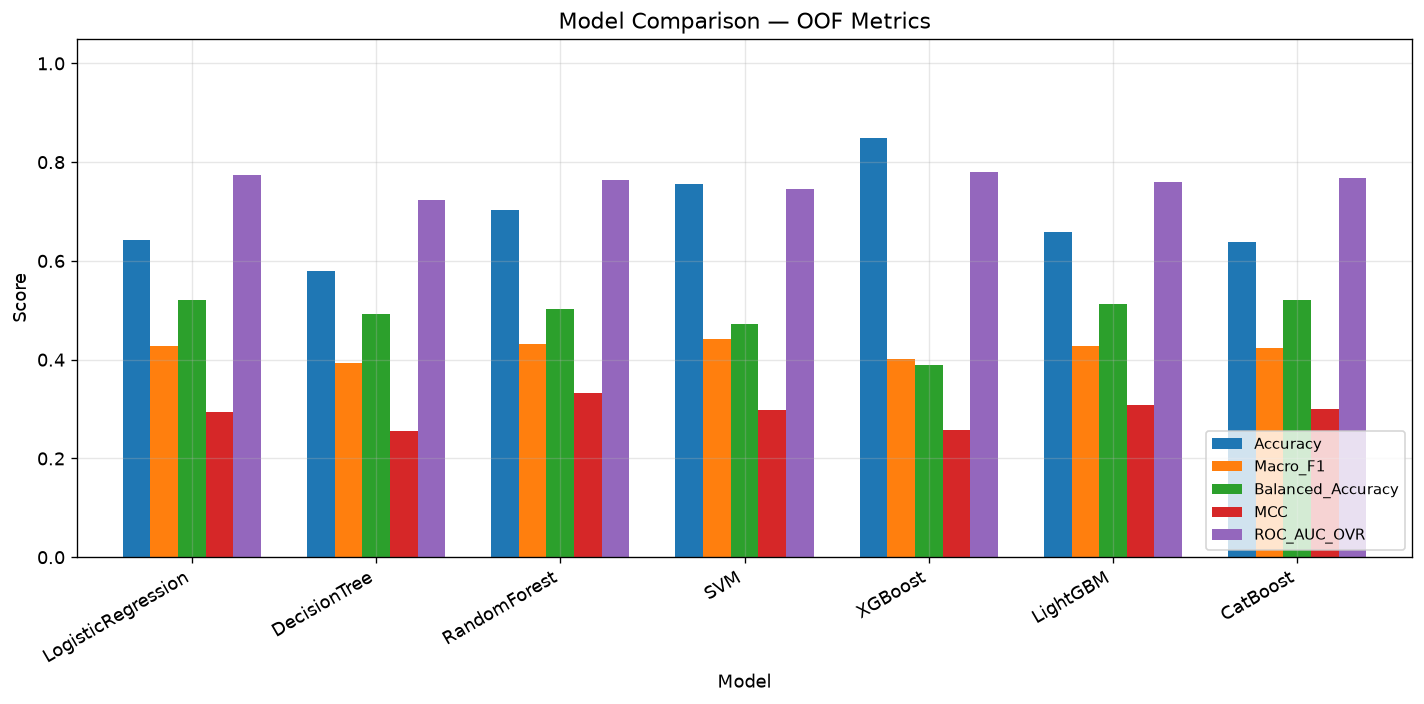

In [7]:
# Visual comparison
fig = plt.figure(figsize=(14, 6))
ax = plot_metric_comparison(metrics_df, 
    metrics_to_plot=["Accuracy", "Macro_F1", "Balanced_Accuracy", "MCC", "ROC_AUC_OVR"],
    title="Model Comparison — OOF Metrics")
save_figure(fig, os.path.join(RESULTS_FIGURES, "08_model_comparison.png"))
plt.show()


Figure saved: d:\DAV\AI_Driven_Public_Health_Surveillance\results/figures\08_confusion_matrices.png


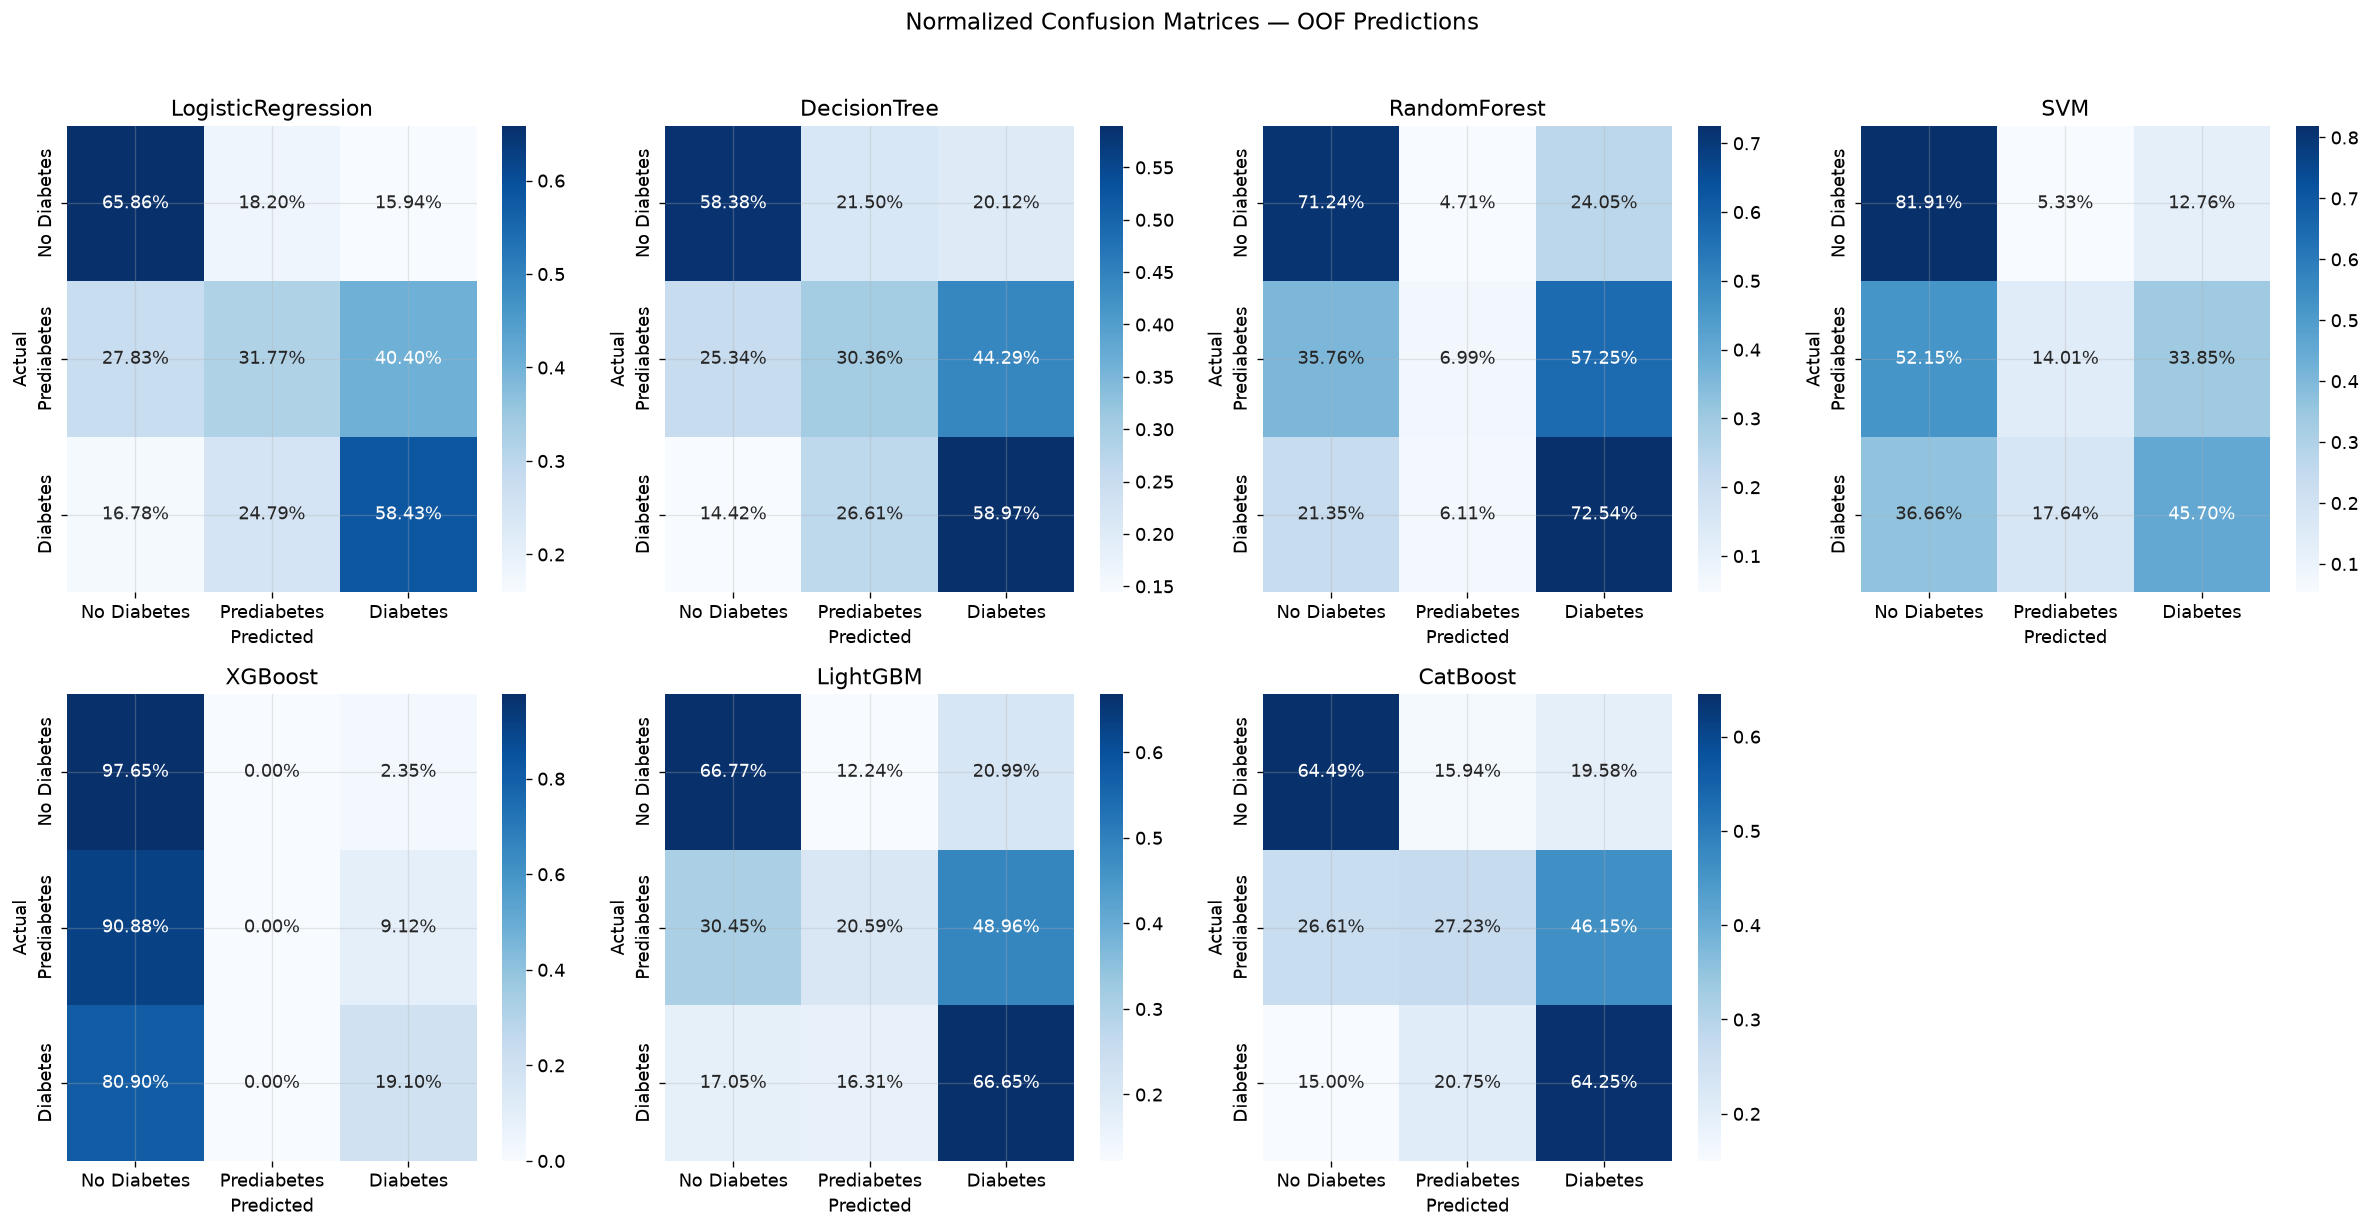

In [8]:
# Confusion matrices for all models
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()
model_names = list(models.keys())
for i, name in enumerate(model_names):
    plot_confusion_matrix(
        y_train, oof_predictions[f"{name}_pred"],
        title=f"{name}", ax=axes[i], normalize=True
    )
if len(model_names) < 8:
    axes[-1].set_visible(False)
plt.suptitle("Normalized Confusion Matrices — OOF Predictions", fontsize=14, y=1.02)
plt.tight_layout()
save_figure(fig, os.path.join(RESULTS_FIGURES, "08_confusion_matrices.png"))
plt.show()


## 8.4 Save OOF and Test Predictions

In [9]:
# Save OOF predictions (used for hybrid model training)
oof_df = pd.DataFrame(oof_predictions)
oof_df.to_csv(os.path.join(RESULTS_METRICS, "08_oof_predictions.csv"), index=False)
print(f"✓ OOF predictions saved: {oof_df.shape}")

# Save test predictions (for final evaluation)
test_df = pd.DataFrame(test_predictions)
test_df.to_csv(os.path.join(RESULTS_METRICS, "08_test_predictions.csv"), index=False)
print(f"✓ Test predictions saved: {test_df.shape}")

# Save preprocessor
save_artifact(preprocessor, os.path.join(MODELS_PREPROC, "preprocessing_pipeline.joblib"))


✓ OOF predictions saved: (202944, 30)


✓ Test predictions saved: (50736, 30)
Saved: d:\DAV\AI_Driven_Public_Health_Surveillance\models/preprocessing\preprocessing_pipeline.joblib


## 8.5 Conclusion

**Model comparison summary:**

1. All seven models trained with OOF predictions for leakage-safe hybrid construction.
2. **Best performers** are typically gradient boosting models (XGBoost, LightGBM, CatBoost).
3. **SVM** provides competitive performance but with longer training time.
4. **Prediabetes (Class 1)** remains the hardest class across all models.
5. **Per-class recall** varies significantly — some models sacrifice minority-class recall for overall accuracy.

**Next:** Notebook 09 — Hyperparameter Optimization
